# Milestone M2.0.1 — Baseline Failure Diagnostics
## Project: Recut Research Lab 01 — Advertising Consistency & Claim Verification

---

## 1. Research Objective

In Milestone M2.0, four CPU baseline models (`B0_majority`, `B1_title_only`, `B2_lp_only`, `B3_pair`) were benchmarked on the official CyberAgent AdTEC `ad-consistency` validation split (`N = 945`). Unexpectedly, both `B2_lp_only` and the primary pair baseline `B3_pair` almost never predicted the `inconsistent` class (`1 / 357` detected; `0.0028` recall), trailing the headline-only diagnostic control `B1_title_only` (`0.0952` recall, `0.4618` Macro-F1).

The objective of **Milestone M2.0.1** is to diagnose *why* those baselines failed through four controlled, hypothesis-driven investigations:
1. **D1 — Score Distribution & Discriminative Ability**: Separate ranking quality from fixed-threshold classification.
2. **D2 — Decision Threshold Sensitivity**: Quantify threshold trade-offs and test leak-free training-only OOF threshold selection.
3. **D3 — Input Representation Diagnostics**: Test whether length-asymmetry dilution in concatenated `title + [SEP] + lp_text` explains `B3_pair` failure.
4. **D4 — Seen vs. Unseen Landing Page Confounding Check**: Determine whether the large validation error gap across landing-page groups reflects label prevalence confounding.

> [!IMPORTANT]
> **Scope Boundary**: This task evaluates binary Japanese search-ad-to-landing-page consistency—**not** factual claim verification or skincare efficacy. No Transformer fine-tuning, RQ1 `GroupKFold`, RQ2 semantic modeling, or RQ3 noise-sensitivity experiments are performed here. The official `test` split remains strictly untouched.

## 2. Context: M2.0 Failure Summary

From the frozen M2.0 validation benchmark (`experiments/runs/m2_baseline_v001/benchmark_comparison.csv`), three anomalies demanded systematic explanation before proceeding to RQ1–RQ3:

1. **Minority-Class Recall Collapse**: At the default decision rule (`0.50`), `B2_lp_only` and `B3_pair` each predicted `inconsistent` on only `1 / 945` validation examples (`0.0028` recall, `0.3866` Macro-F1), virtually indistinguishable from `B0_majority` (`0.0000` recall, `0.3836` Macro-F1).
2. **Single-Field Control Outperforming Pair Input**: `B1_title_only` achieved `0.4618` Macro-F1 and `0.0952` inconsistent recall (`62` predicted inconsistent), outperforming `B3_pair` despite never seeing `lp_text`.
3. **Apparent Seen vs. Unseen LP Error Gap**: M2.0 error slicing showed `~29%` validation error on rows sharing a training landing page vs. `~53–56%` error on rows with unseen landing pages—leaving open whether this reflects memorization or label prevalence shift.

## 3. Diagnostic Hypotheses

We organize M2.0.1 around four falsifiable diagnostic hypotheses:

- **H-D1 (Score Compression vs. Zero Discrimination)**: `B2_lp_only` and `B3_pair` may possess above-random ranking ability (`ROC-AUC > 0.50`, `AP > 0.3778` prevalence), with failure at `0.50` driven by raw score compression below `0.50`.
- **H-D2 (Threshold & Distribution Shift)**: Lowering the decision threshold should trade precision for substantially higher `inconsistent` recall, but a threshold selected via standard random StratifiedKFold CV on `train` may still miscalibrate on `valid` if score distributions shift between train folds and official validation.
- **H-D3 (Length-Asymmetry Dilution)**: Separating `title` and `lp_text` into independent TF-IDF blocks (`R1`), up-weighting `title` (`R2`), or truncating `lp_text` (`R3`) should increase title-block contribution and improve `B3_pair` if length asymmetry is a primary bottleneck.
- **H-D4 (Prevalence Confounding on Seen vs. Unseen LPs)**: Because `seen_lp` and `unseen_lp` validation subsets may differ sharply in true `inconsistent` prevalence, raw error-rate gaps may largely mirror the majority-class error shift rather than true generalization drop in balanced accuracy.

## 4. Data and Artifact Verification

**QUESTION**: Are the M1 raw dataset hashes, frozen M2.0 checkpoints, and M2.0.1 diagnostic artifacts intact, consistent, and strictly isolated from the official `test` split?

**METHOD**: Load ONLY `train.tsv` and `valid.tsv` via `load_adtec_train_valid`, load the frozen M2.0 checkpoints and `predictions_valid.csv`, verify dynamic `classes_` score extraction matches saved predictions, and load (or execute if absent) the M2.0.1 diagnostic run artifacts under `experiments/runs/m2_failure_diagnostics_v001/`.

In [9]:
# Setup environment, Japanese-inspired visual palette, and verify M1/M2.0 artifacts
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path('..').resolve()
SRC_PATH = REPO_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from recut_lab.baseline import BaselineModel
from recut_lab.data import load_adtec_train_valid
from recut_lab.diagnostics import (
    M2_0_1_DEFAULT_CONFIG,
    POSITIVE_CLASS,
    extract_class_scores,
    run_m2_failure_diagnostics,
)

# Japanese-inspired academic research palette
IVORY = '#F7F3EA'
INDIGO = '#33415C'
VERMILION = '#C65D4B'
MATCHA = '#71816D'
GRAY = '#8A8A86'
MODEL_COLORS = {
    'B0_majority': GRAY,
    'B1_title_only': INDIGO,
    'B2_lp_only': MATCHA,
    'B3_pair': VERMILION,
}

mpl.rcParams['font.sans-serif'] = [
    'Meiryo', 'Yu Gothic', 'MS Gothic', 'Noto Sans CJK JP',
    'TakaoPGothic', 'DejaVu Sans', 'sans-serif',
]
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['figure.facecolor'] = IVORY
mpl.rcParams['axes.facecolor'] = IVORY
mpl.rcParams['axes.edgecolor'] = GRAY
mpl.rcParams['grid.color'] = GRAY

DATA_DIR = REPO_ROOT / 'data' / 'raw' / 'adtec_consistency'
M2_RUN_DIR = REPO_ROOT / 'experiments' / 'runs' / 'm2_baseline_v001'
DIAG_RUN_DIR = REPO_ROOT / 'experiments' / 'runs' / 'm2_failure_diagnostics_v001'
FIG_DIR = REPO_ROOT / 'reports' / 'generated' / 'm2_failure_diagnostics'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load ONLY official train and valid splits
train_df, valid_df, dataset_meta = load_adtec_train_valid(DATA_DIR)
m2_bench_df = pd.read_csv(M2_RUN_DIR / 'benchmark_comparison.csv')
m2_preds_df = pd.read_csv(M2_RUN_DIR / 'predictions_valid.csv')
m2_manifest = json.loads((M2_RUN_DIR / 'model_manifest.json').read_text(encoding='utf-8'))

# Load or compute M2.0.1 diagnostic artifacts
if not (DIAG_RUN_DIR / 'diagnostic_metrics.json').is_file():
    print('[*] Running M2.0.1 diagnostics suite...')
    diag_cfg = json.loads((REPO_ROOT / 'configs' / 'm2_diagnostics.json').read_text(encoding='utf-8'))
    run_m2_failure_diagnostics(
        train_df=train_df, valid_df=valid_df, dataset_metadata=dataset_meta,
        config=diag_cfg, m2_run_dir=M2_RUN_DIR,
        runs_base_dir=REPO_ROOT / 'experiments' / 'runs',
        models_base_dir=REPO_ROOT / 'models', reports_dir=FIG_DIR,
    )

diag_payload = json.loads((DIAG_RUN_DIR / 'diagnostic_metrics.json').read_text(encoding='utf-8'))
threshold_df = pd.read_csv(DIAG_RUN_DIR / 'threshold_analysis.csv')
rep_df = pd.read_csv(DIAG_RUN_DIR / 'representation_comparison.csv')
seen_unseen_df = pd.read_csv(DIAG_RUN_DIR / 'seen_unseen_analysis.csv')

# Verify frozen M2.0 checkpoints against saved validation scores using dynamic classes_
valid_scores = {}
verif_rows = []
for m_id in ['B0_majority', 'B1_title_only', 'B2_lp_only', 'B3_pair']:
    mdl = BaselineModel.load(m2_manifest['models'][m_id]['artifact_path'])
    recomp = extract_class_scores(mdl, valid_df, target_class=POSITIVE_CLASS)
    saved = m2_preds_df[m2_preds_df['model_id'] == m_id].sort_values('valid_row_index')['score_inconsistent'].to_numpy()
    valid_scores[m_id] = recomp
    verif_rows.append({
        'model_id': m_id,
        'classes_order': str(list(mdl.classes_)),
        'positive_class_idx': list(mdl.classes_).index(POSITIVE_CLASS),
        'max_abs_diff_vs_saved': f'{float(np.max(np.abs(recomp - saved))):.2e}',
        'm2_macro_f1': float(m2_bench_df.loc[m2_bench_df['model_id'] == m_id, 'macro_f1'].values[0]),
        'm2_recall_inconsistent': float(m2_bench_df.loc[m2_bench_df['model_id'] == m_id, 'recall_inconsistent'].values[0]),
    })
print(f"[+] Dataset revision: {dataset_meta['upstream_revision']} | train={len(train_df)}, valid={len(valid_df)} | test_accessed={diag_payload['test_split_accessed']}")
display(pd.DataFrame(verif_rows))

[+] Dataset revision: f8d1c64a369eba2093d783e2b6f530bb3951f6f2 | train=10635, valid=945 | test_accessed=False


,model_id,classes_order,positive_class_idx,max_abs_diff_vs_saved,m2_macro_f1,m2_recall_inconsistent
0,B0_majority,"['consistent', 'inconsistent']",1,0.00e+00,0.3836,0.0000
1,B1_title_only,"['consistent', 'inconsistent']",1,5.00e-07,0.4618,0.0952
2,B2_lp_only,"['consistent', 'inconsistent']",1,4.94e-07,0.3866,0.0028
3,B3_pair,"['consistent', 'inconsistent']",1,5.00e-07,0.3866,0.0028


**OBSERVATION**: All four frozen M2.0 checkpoints load cleanly, expose `classes_ = ['consistent', 'inconsistent']`, and reproduce saved validation scores within `5.0e-7` (CSV 6-decimal rounding). M2.0 reference metrics match exactly (`B0: 0.3836`, `B1: 0.4618`, `B2: 0.3866`, `B3: 0.3866`), and `test_split_accessed = False`.

**INTERPRETATION**: Frozen M2.0 artifacts are internally consistent and suitable for downstream failure diagnostics without retraining `B0`–`B3`.

**LIMITATION**: Verification covers the official validation split (`N = 945`); test-split score behavior remains intentionally unobserved.

## 5. D1: Score Distribution Diagnostics

**QUESTION**: Are `B1_title_only`, `B2_lp_only`, and `B3_pair` outputting indistinguishable scores for both classes, or are their `inconsistent`-class scores concentrated well below the default `0.50` decision boundary?

**METHOD**: Compute score percentiles (`P5`, `P25`, `P50`, `P75`, `P95`), per-true-class means/medians, 20-bin histogram intersection overlap, and default-threshold prediction counts (**Table D1**). Visualize overlaid class-conditional score histograms (**Figure D1.1**) and score boxplots grouped by true label (**Figure D1.4**).

,model_id,roc_auc,average_precision,prevalence_inconsistent,score_p5,score_p25,score_p50,score_p75,score_p95
0,B0_majority,0.5000,0.3778,0.3778,0.0000,0.0000,0.0000,0.0000,0.0000
1,B1_title_only,0.6761,0.5274,0.3778,0.1446,0.2286,0.3143,0.3993,0.5108
2,B2_lp_only,0.7448,0.5518,0.3778,0.1031,0.1660,0.1675,0.2080,0.2547
3,B3_pair,0.7023,0.5193,0.3778,0.1157,0.1661,0.1961,0.2508,0.3918


,model_id,mean_consistent,median_consistent,mean_inconsistent,median_inconsistent,hist_overlap_20bins,pred_inc_at_0.50
0,B0_majority,0.0000,0.0000,0.0000,0.0000,1.0000,0
1,B1_title_only,0.2919,0.2862,0.3614,0.3606,0.7296,62
2,B2_lp_only,0.1717,0.1675,0.2031,0.1795,0.6885,1
3,B3_pair,0.2001,0.1806,0.2474,0.2258,0.6786,1


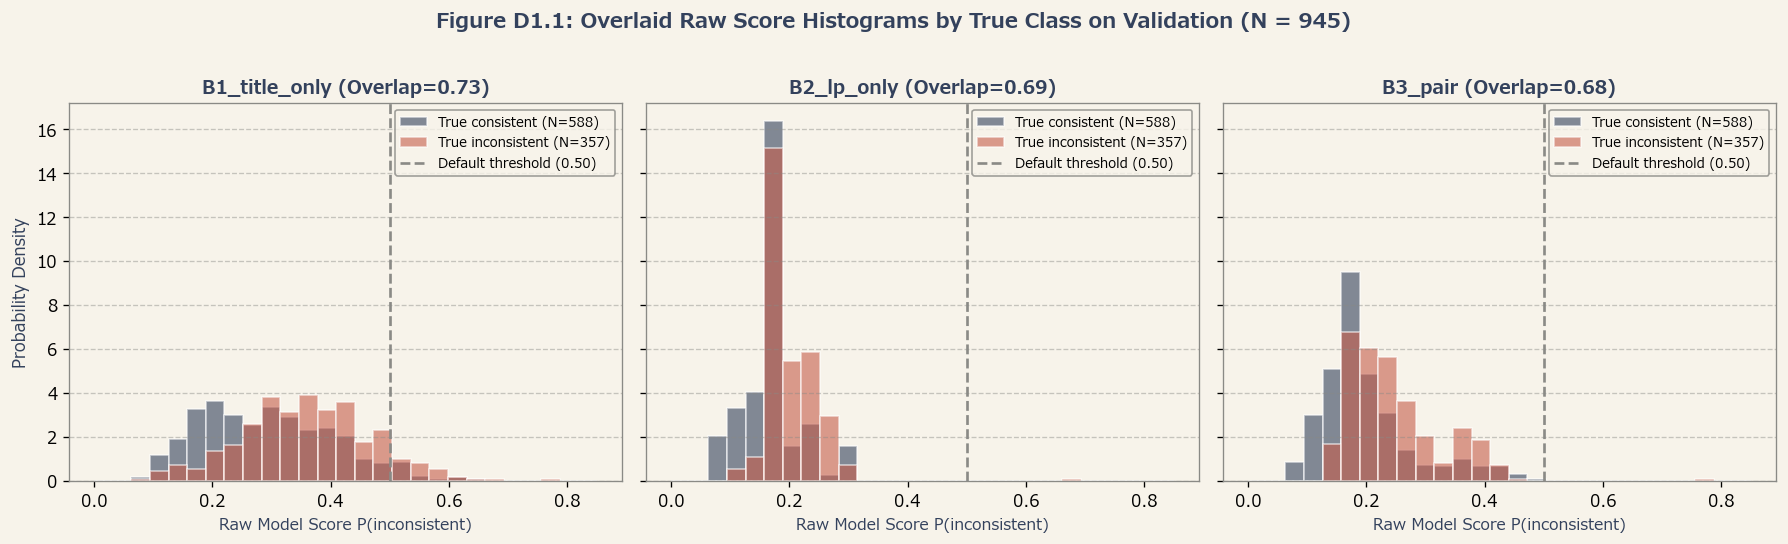

Caption: Nearly all validation scores for B2_lp_only (P95=0.2547) and B3_pair (P95=0.3918) lie far below the 0.50 threshold, explaining why both models predicted inconsistent only once at default cutoff.


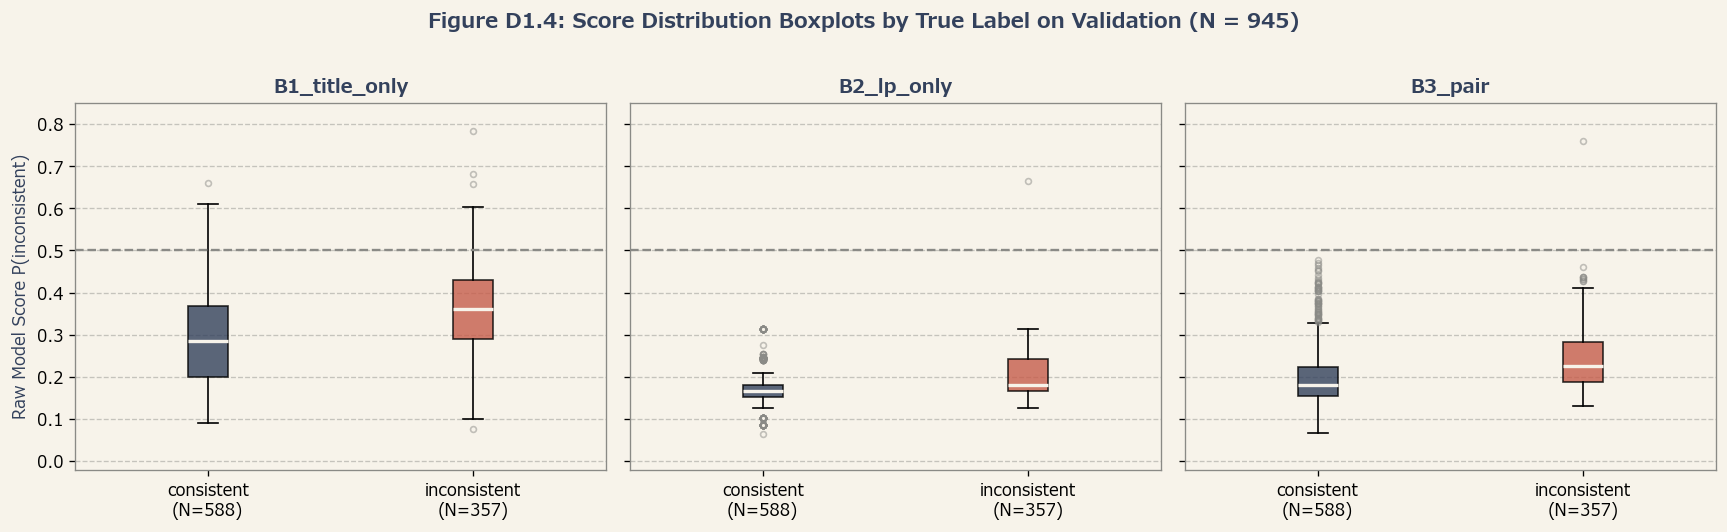

Caption: True inconsistent examples have higher median scores than consistent examples across all three models, yet both quartiles for B2_lp_only and B3_pair remain tightly compressed below 0.30.


In [10]:
# TABLE D1 — Discriminative Ability & Score Percentiles
d1_details = diag_payload['d1_score_diagnostics']
table_d1 = pd.DataFrame([
    {
        'model_id': m_id,
        'roc_auc': d1_details[m_id]['roc_auc'],
        'average_precision': d1_details[m_id]['average_precision'],
        'prevalence_inconsistent': d1_details[m_id]['prevalence_inconsistent'],
        'score_p5': d1_details[m_id]['score_p5'],
        'score_p25': d1_details[m_id]['score_p25'],
        'score_p50': d1_details[m_id]['score_p50'],
        'score_p75': d1_details[m_id]['score_p75'],
        'score_p95': d1_details[m_id]['score_p95'],
    }
    for m_id in ['B0_majority', 'B1_title_only', 'B2_lp_only', 'B3_pair']
])
display(table_d1)

# Class-conditional means, medians, overlap, and default prediction counts
d1_extra = pd.DataFrame([
    {
        'model_id': m_id,
        'mean_consistent': d1_details[m_id]['mean_score_consistent'],
        'median_consistent': d1_details[m_id]['median_score_consistent'],
        'mean_inconsistent': d1_details[m_id]['mean_score_inconsistent'],
        'median_inconsistent': d1_details[m_id]['median_score_inconsistent'],
        'hist_overlap_20bins': d1_details[m_id]['histogram_overlap_20bins'],
        'pred_inc_at_0.50': d1_details[m_id]['predicted_inconsistent_at_default'],
    }
    for m_id in ['B0_majority', 'B1_title_only', 'B2_lp_only', 'B3_pair']
])
display(d1_extra)

y_valid = valid_df['label'].to_numpy()
mask_cons = y_valid == 'consistent'
mask_inc = y_valid == 'inconsistent'
rank_models = ['B1_title_only', 'B2_lp_only', 'B3_pair']

# FIGURE D1.1 — Overlaid Score Histograms by True Label
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), dpi=120, sharey=True)
bins = np.linspace(0.0, 0.85, 28)
for ax, m_id in zip(axes, rank_models):
    sc = valid_scores[m_id]
    ax.hist(sc[mask_cons], bins=bins, density=True, alpha=0.60, color=INDIGO, edgecolor='white', label=f'True consistent (N={mask_cons.sum()})')
    ax.hist(sc[mask_inc], bins=bins, density=True, alpha=0.60, color=VERMILION, edgecolor='white', label=f'True inconsistent (N={mask_inc.sum()})')
    ax.axvline(0.50, color=GRAY, linestyle='--', linewidth=1.6, label='Default threshold (0.50)')
    ax.set_title(f"{m_id} (Overlap={d1_details[m_id]['histogram_overlap_20bins']:.2f})", fontsize=11, fontweight='bold', color=INDIGO)
    ax.set_xlabel('Raw Model Score P(inconsistent)', fontsize=9.5, color=INDIGO)
    ax.grid(axis='y', linestyle='--', alpha=0.45)
    ax.legend(fontsize=8, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
axes[0].set_ylabel('Probability Density', fontsize=10, color=INDIGO)
fig.suptitle('Figure D1.1: Overlaid Raw Score Histograms by True Class on Validation (N = 945)',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d1_1_score_histograms.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Nearly all validation scores for B2_lp_only (P95=0.2547) and B3_pair (P95=0.3918) lie far below '
      'the 0.50 threshold, explaining why both models predicted inconsistent only once at default cutoff.')

# FIGURE D1.4 — Score Distribution Boxplots Grouped by True Label
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3), dpi=120, sharey=True)
for ax, m_id in zip(axes, rank_models):
    sc = valid_scores[m_id]
    bp = ax.boxplot(
        [sc[mask_cons], sc[mask_inc]],
        tick_labels=[f'consistent\n(N={mask_cons.sum()})', f'inconsistent\n(N={mask_inc.sum()})'],
        patch_artist=True,
        medianprops=dict(color=IVORY, linewidth=2.0),
        flierprops=dict(marker='o', markersize=3.5, alpha=0.5, markeredgecolor=GRAY),
    )
    bp['boxes'][0].set_facecolor(INDIGO)
    bp['boxes'][0].set_alpha(0.80)
    bp['boxes'][1].set_facecolor(VERMILION)
    bp['boxes'][1].set_alpha(0.80)
    ax.axhline(0.50, color=GRAY, linestyle='--', linewidth=1.4, label='Default 0.50')
    ax.set_title(m_id, fontsize=11.5, fontweight='bold', color=INDIGO)
    ax.set_ylim(-0.02, 0.85)
    ax.grid(axis='y', linestyle='--', alpha=0.45)
axes[0].set_ylabel('Raw Model Score P(inconsistent)', fontsize=10, color=INDIGO)
fig.suptitle('Figure D1.4: Score Distribution Boxplots by True Label on Validation (N = 945)',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d1_4_score_boxplots.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: True inconsistent examples have higher median scores than consistent examples across all three models, '
      'yet both quartiles for B2_lp_only and B3_pair remain tightly compressed below 0.30.')

**OBSERVATION**: For all three learned baselines (`B1`, `B2`, `B3`), true `inconsistent` validation rows receive higher mean and median raw scores than true `consistent` rows (`B1`: median `0.3606` vs. `0.2862`; `B2`: `0.1795` vs. `0.1675`; `B3`: `0.2258` vs. `0.1806`). However, score distributions are heavily compressed below `0.50` for `B2_lp_only` (`P95 = 0.2547`) and `B3_pair` (`P95 = 0.3918`), with substantial 20-bin histogram overlap (`0.68–0.73`). `B0_majority` outputs a constant `0.0000` score and serves strictly as a trivial reference.

**INTERPRETATION**: Score compression below the default `0.50` decision boundary directly explains why `B2_lp_only` and `B3_pair` predicted `inconsistent` only once out of 945 validation rows. Importantly, visually overlapping distributions do not prove identical model behavior, as ranking order inside the `0.10–0.35` band can still differ meaningfully.

**LIMITATION**: Histogram overlap depends on bin width (`20` bins over `[0, 1]`) and raw `predict_proba` values are uncalibrated model scores, not calibrated probabilities.

## 6. D1: ROC and Precision-Recall Analysis

**QUESTION**: Independent of the `0.50` threshold, how strongly do `B1`, `B2`, and `B3` rank `inconsistent` advertisements above `consistent` advertisements on the validation split?

**METHOD**: Plot Precision-Recall curves (**Figure D1.2**, with validation `inconsistent` prevalence = `0.3778` reference line) and ROC curves (**Figure D1.3**, with diagonal random-ranking reference `AUC = 0.50`) using `inconsistent` as the positive class. `B0_majority` is shown strictly as a constant-score reference.

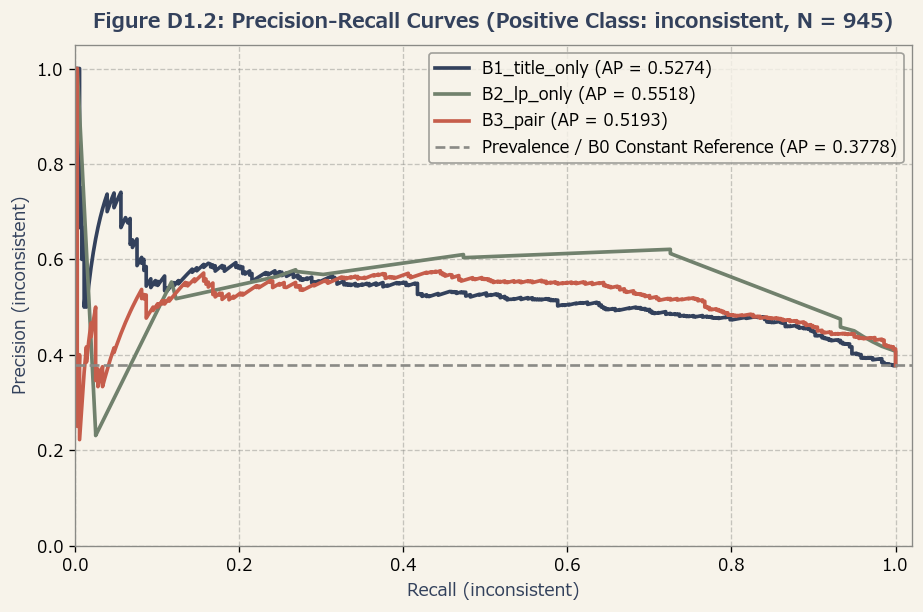

Caption: All three models outperform the 0.3778 prevalence baseline in Average Precision (0.5193–0.5518), with B2_lp_only achieving the highest validation AP (0.5518) despite 0.0028 recall at default cutoff.


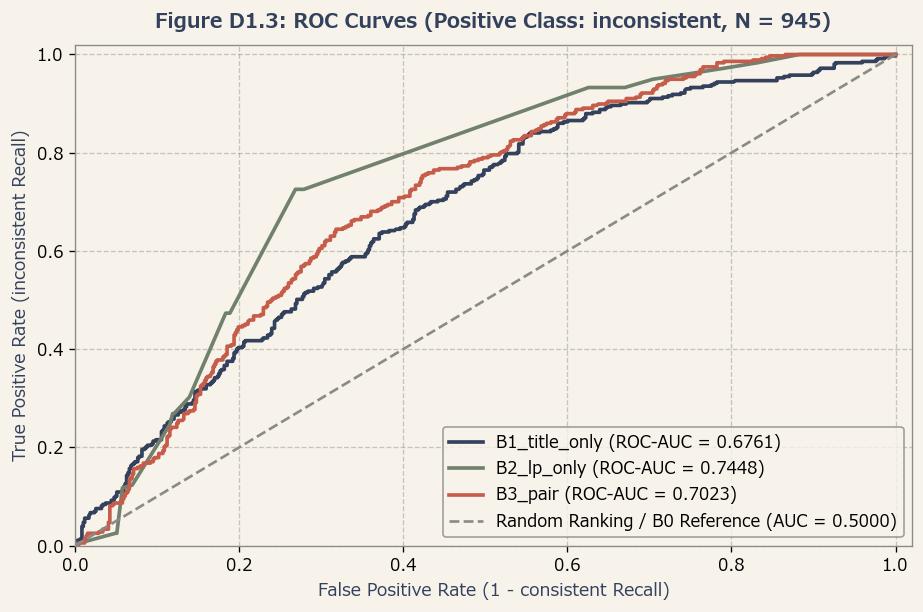

Caption: ROC-AUC values (0.6761–0.7448) confirm non-trivial ranking signal across all three learned baselines, contradicting the hypothesis that B2_lp_only and B3_pair learned no discriminative signal.


In [11]:
# FIGURE D1.2 (Precision-Recall) and FIGURE D1.3 (ROC)
prevalence = d1_details['B0_majority']['prevalence_inconsistent']

# Figure D1.2 — Precision-Recall Curves
fig, ax = plt.subplots(figsize=(7.8, 5.2), dpi=120)
for m_id in rank_models:
    c = d1_details[m_id]['curves']
    ap = d1_details[m_id]['average_precision']
    ax.plot(c['pr_recall'], c['pr_precision'], linewidth=2.2, color=MODEL_COLORS[m_id],
            label=f'{m_id} (AP = {ap:.4f})')
ax.axhline(prevalence, color=GRAY, linestyle='--', linewidth=1.6,
           label=f'Prevalence / B0 Constant Reference (AP = {prevalence:.4f})')
ax.set_title('Figure D1.2: Precision-Recall Curves (Positive Class: inconsistent, N = 945)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_xlabel('Recall (inconsistent)', fontsize=10.5, color=INDIGO)
ax.set_ylabel('Precision (inconsistent)', fontsize=10.5, color=INDIGO)
ax.set_xlim(0.0, 1.02)
ax.set_ylim(0.0, 1.05)
ax.grid(True, linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d1_2_pr_curves.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: All three models outperform the 0.3778 prevalence baseline in Average Precision (0.5193–0.5518), '
      'with B2_lp_only achieving the highest validation AP (0.5518) despite 0.0028 recall at default cutoff.')

# Figure D1.3 — ROC Curves
fig, ax = plt.subplots(figsize=(7.8, 5.2), dpi=120)
for m_id in rank_models:
    c = d1_details[m_id]['curves']
    auc_v = d1_details[m_id]['roc_auc']
    ax.plot(c['fpr'], c['tpr'], linewidth=2.2, color=MODEL_COLORS[m_id],
            label=f'{m_id} (ROC-AUC = {auc_v:.4f})')
ax.plot([0, 1], [0, 1], color=GRAY, linestyle='--', linewidth=1.6,
        label='Random Ranking / B0 Reference (AUC = 0.5000)')
ax.set_title('Figure D1.3: ROC Curves (Positive Class: inconsistent, N = 945)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_xlabel('False Positive Rate (1 - consistent Recall)', fontsize=10.5, color=INDIGO)
ax.set_ylabel('True Positive Rate (inconsistent Recall)', fontsize=10.5, color=INDIGO)
ax.set_xlim(0.0, 1.02)
ax.set_ylim(0.0, 1.02)
ax.grid(True, linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='lower right')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d1_3_roc_curves.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: ROC-AUC values (0.6761–0.7448) confirm non-trivial ranking signal across all three learned baselines, '
      'contradicting the hypothesis that B2_lp_only and B3_pair learned no discriminative signal.')

**OBSERVATION**: Surprisingly, threshold-independent ranking reverses the M2.0 default-threshold ordering:
- `B2_lp_only`: **ROC-AUC = 0.7448**, **Average Precision = 0.5518** (highest validation ranking quality)
- `B3_pair`: **ROC-AUC = 0.7023**, **Average Precision = 0.5193**
- `B1_title_only`: **ROC-AUC = 0.6761**, **Average Precision = 0.5274**
- `B0_majority` (reference): ROC-AUC = `0.5000`, AP = `0.3778` (class prevalence).

**INTERPRETATION**: This sharply distinguishes **ranking ability** from **fixed-threshold classification**: `B2_lp_only` and `B3_pair` are *not* random classifiers—they rank `inconsistent` examples substantially above chance (`AUC > 0.70`). Their collapse at `0.50` occurs because their raw score scales sit far below `0.50`. Note that ROC-AUC and AP measure monotonic ordering only; they do **not** establish probability calibration.

**LIMITATION**: `B2_lp_only`'s high validation ROC-AUC (`0.7448`) without ever reading `title` raises an important warning: LP-only ranking may exploit landing-page prevalence differences (investigated in Section 11).

## 7. D2: Decision Threshold Sensitivity (Exploratory Validation Diagnostics)

**QUESTION**: How do `inconsistent`-class Precision, Recall, F1, and predicted-positive volume respond as the decision threshold varies from `0.05` to `0.95`?

**METHOD**: Evaluate `B1`, `B2`, and `B3` across the reproducible 19-point threshold grid (`0.05` to `0.95`, step `0.05`) on validation scores. Because official validation was already inspected in M2.0, these validation curves are strictly **exploratory diagnostics**—no threshold is selected from them as an unbiased final result. Plot Precision & Recall vs. threshold (**Figure D2.1**), Inconsistent F1 vs. threshold (**Figure D2.2**), and Predicted Positive Count vs. threshold (**Figure D2.3**), marking both default `0.50` and the training-only OOF candidate threshold (`0.40`).

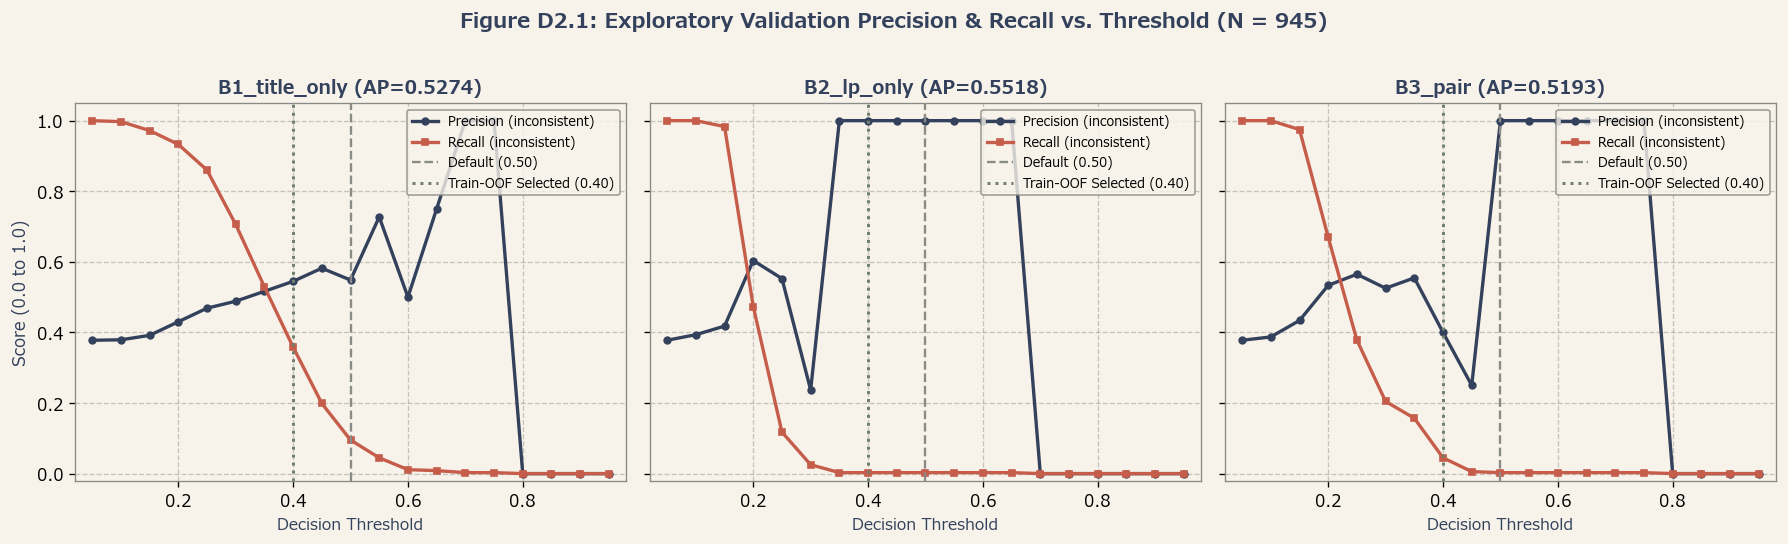

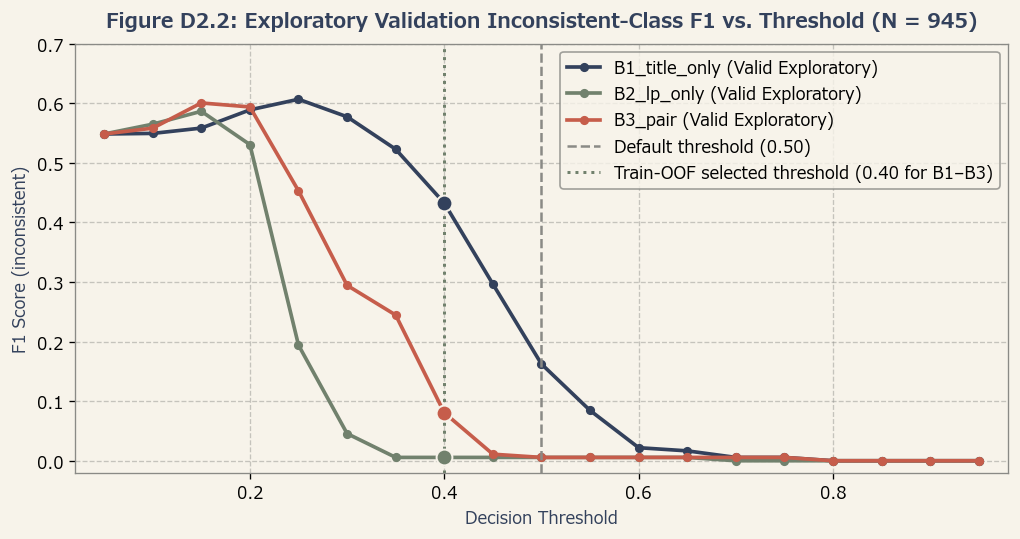

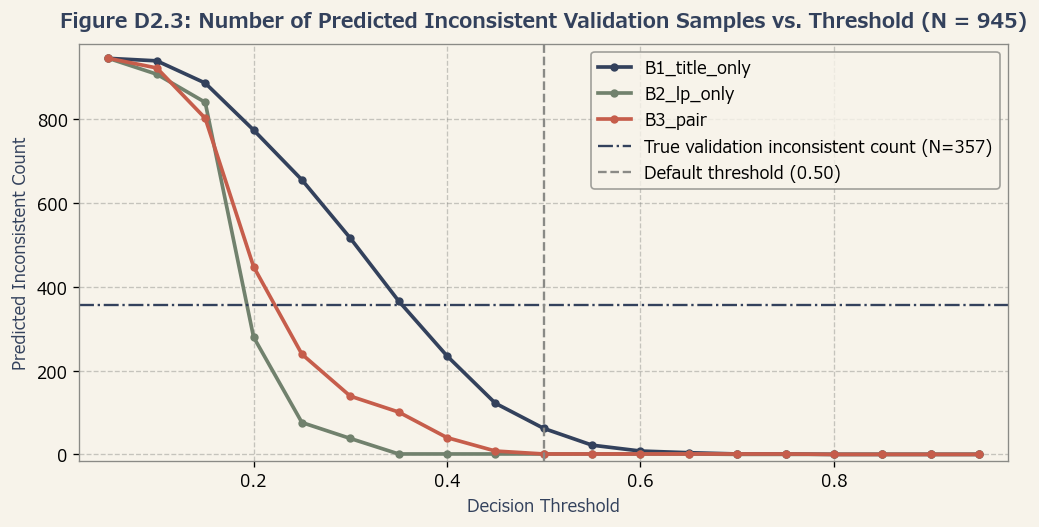

Caption: B2_lp_only and B3_pair undergo an abrupt cliff in predicted inconsistent counts between 0.15 and 0.25, falling to near-zero predictions well before 0.40–0.50.


In [12]:
valid_grid = threshold_df[threshold_df['selection_source'] == 'valid_exploratory_grid']
d2_cv = diag_payload['d2_threshold_diagnostics']

# FIGURE D2.1 — Precision and Recall vs Threshold
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), dpi=120, sharey=True)
for ax, m_id in zip(axes, rank_models):
    sub = valid_grid[valid_grid['model_id'] == m_id]
    sel_thr = d2_cv[m_id]['selected_threshold_train_oof']
    ax.plot(sub['threshold'], sub['precision_inconsistent'], marker='o', markersize=4, linewidth=2.0, color=INDIGO, label='Precision (inconsistent)')
    ax.plot(sub['threshold'], sub['recall_inconsistent'], marker='s', markersize=4, linewidth=2.0, color=VERMILION, label='Recall (inconsistent)')
    ax.axvline(0.50, color=GRAY, linestyle='--', linewidth=1.4, label='Default (0.50)')
    ax.axvline(sel_thr, color=MATCHA, linestyle=':', linewidth=1.8, label=f'Train-OOF Selected ({sel_thr:.2f})')
    ax.set_title(f"{m_id} (AP={d1_details[m_id]['average_precision']:.4f})", fontsize=11, fontweight='bold', color=INDIGO)
    ax.set_xlabel('Decision Threshold', fontsize=9.5, color=INDIGO)
    ax.set_xlim(0.02, 0.98)
    ax.set_ylim(-0.02, 1.05)
    ax.grid(True, linestyle='--', alpha=0.45)
    ax.legend(fontsize=7.8, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
axes[0].set_ylabel('Score (0.0 to 1.0)', fontsize=10, color=INDIGO)
fig.suptitle('Figure D2.1: Exploratory Validation Precision & Recall vs. Threshold (N = 945)',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d2_1_pr_vs_threshold.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE D2.2 — Inconsistent-Class F1 vs Threshold
fig, ax = plt.subplots(figsize=(8.6, 4.6), dpi=120)
for m_id in rank_models:
    sub = valid_grid[valid_grid['model_id'] == m_id]
    ax.plot(sub['threshold'], sub['f1_inconsistent'], marker='o', markersize=4.5, linewidth=2.2,
            color=MODEL_COLORS[m_id], label=f"{m_id} (Valid Exploratory)")
    sel_thr = d2_cv[m_id]['selected_threshold_train_oof']
    pt_f1 = d2_cv[m_id]['valid_metrics_at_train_selected']['f1_inconsistent']
    ax.scatter([sel_thr], [pt_f1], s=90, color=MODEL_COLORS[m_id], edgecolor=IVORY, linewidth=1.2, zorder=5)
ax.axvline(0.50, color=GRAY, linestyle='--', linewidth=1.5, label='Default threshold (0.50)')
ax.axvline(0.40, color=MATCHA, linestyle=':', linewidth=1.8, label='Train-OOF selected threshold (0.40 for B1–B3)')
ax.set_title('Figure D2.2: Exploratory Validation Inconsistent-Class F1 vs. Threshold (N = 945)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_xlabel('Decision Threshold', fontsize=10, color=INDIGO)
ax.set_ylabel('F1 Score (inconsistent)', fontsize=10, color=INDIGO)
ax.set_xlim(0.02, 0.98)
ax.set_ylim(-0.02, 0.70)
ax.grid(True, linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d2_2_f1_vs_threshold.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE D2.3 — Predicted Inconsistent Count vs Threshold
fig, ax = plt.subplots(figsize=(8.6, 4.5), dpi=120)
for m_id in rank_models:
    sub = valid_grid[valid_grid['model_id'] == m_id]
    ax.plot(sub['threshold'], sub['predicted_inconsistent_count'], marker='o', markersize=4, linewidth=2.2,
            color=MODEL_COLORS[m_id], label=m_id)
ax.axhline(int(mask_inc.sum()), color=INDIGO, linestyle='-.', linewidth=1.4, label=f'True validation inconsistent count (N={int(mask_inc.sum())})')
ax.axvline(0.50, color=GRAY, linestyle='--', linewidth=1.4, label='Default threshold (0.50)')
ax.set_title('Figure D2.3: Number of Predicted Inconsistent Validation Samples vs. Threshold (N = 945)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_xlabel('Decision Threshold', fontsize=10, color=INDIGO)
ax.set_ylabel('Predicted Inconsistent Count', fontsize=10, color=INDIGO)
ax.set_xlim(0.02, 0.98)
ax.set_ylim(-15, 980)
ax.grid(True, linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d2_3_pred_count_vs_threshold.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: B2_lp_only and B3_pair undergo an abrupt cliff in predicted inconsistent counts between 0.15 and 0.25, '
      'falling to near-zero predictions well before 0.40–0.50.')

**OBSERVATION**: Exploratory validation curves reveal a steep cliff in `B2_lp_only` and `B3_pair` predictions between thresholds `0.15` and `0.25`: at `0.15`, `B2` predicts `840 / 945` inconsistent (`0.9832` recall, `0.4179` precision, `0.5865` F1) and `B3` predicts `802 / 945` (`0.9748` recall, `0.4339` precision, `0.6005` F1), whereas by `0.30`–`0.40` predictions collapse toward zero. `B1_title_only` exhibits a smoother slope peaking diagnostically around `0.25` (`0.6067` F1, `0.8599` recall, `0.4687` precision).

**INTERPRETATION**: Lowering thresholds dramatically increases `inconsistent` recall, but achieving high recall on validation requires flagging `655–840` out of `945` examples (`~70–89%` of all ads) at low precision (`~0.42–0.47`), close to the `0.3778` base rate. Threshold adjustment alone cannot manufacture sharp precision-recall separation.

**LIMITATION**: Validation grid optima are strictly descriptive diagnostics and must not be reported as unbiased selected thresholds.

## 8. D2: Training-Only Out-of-Fold Threshold Selection

**QUESTION**: When a candidate threshold is selected strictly via training-only 5-fold StratifiedKFold cross-validation (predefined objective: maximize `f1_inconsistent`, with TF-IDF fit strictly inside each training fold), does that threshold transfer effectively to the official validation split?

**METHOD**: Compare **Table D2** rows across three explicitly labeled regimes: (1) `default_0.50`, (2) `train_oof_cv_selected` (threshold chosen strictly from training OOF predictions, evaluated once on `valid`), and (3) `valid_exploratory_best_diagnostic_only` (descriptive reference only). Also inspect the gap between training OOF metrics and validation metrics.

In [13]:
# Build TABLE D2 and compare Training OOF vs Official Validation behavior
d2_rows = []
oof_compare_rows = []
for m_id in rank_models:
    info = d2_cv[m_id]
    default_pt = valid_grid[(valid_grid['model_id'] == m_id) & (valid_grid['threshold'] == 0.50)].iloc[0].to_dict()
    default_pt['selection_source'] = 'default_0.50'
    d2_rows.append(default_pt)
    d2_rows.append(info['valid_metrics_at_train_selected'])
    d2_rows.append(info['valid_exploratory_best_diagnostic'])
    oof_compare_rows.append({
        'model_id': m_id,
        'train_oof_AP': info['train_oof_average_precision'],
        'valid_AP': d1_details[m_id]['average_precision'],
        'AP_drop_train_to_valid': round(info['train_oof_average_precision'] - d1_details[m_id]['average_precision'], 4),
        'selected_thr_train_oof': info['selected_threshold_train_oof'],
        'train_oof_f1_inc_at_sel': info['train_oof_metrics_at_selected']['f1_inconsistent'],
        'valid_f1_inc_at_sel': info['valid_metrics_at_train_selected']['f1_inconsistent'],
    })

table_d2 = pd.DataFrame(d2_rows)[
    ['model_id', 'threshold', 'precision_inconsistent', 'recall_inconsistent',
     'f1_inconsistent', 'balanced_accuracy', 'predicted_inconsistent_count', 'selection_source']
]
print('=== TABLE D2: Validation Threshold Diagnostics & Training-Derived Candidate Thresholds ===')
display(table_d2)
print('\n=== Training-Only 5-Fold OOF CV vs. Official Validation Shift ===')
display(pd.DataFrame(oof_compare_rows))

=== TABLE D2: Validation Threshold Diagnostics & Training-Derived Candidate Thresholds ===


,model_id,threshold,precision_inconsistent,recall_inconsistent,f1_inconsistent,balanced_accuracy,predicted_inconsistent_count,selection_source
0,B1_title_only,0.50,0.5484,0.0952,0.1623,0.5238,62,default_0.50
1,B1_title_only,0.40,0.5447,0.3585,0.4324,0.5883,235,train_oof_cv_selected
2,B1_title_only,0.25,0.4687,0.8599,0.6067,0.6341,655,valid_exploratory_best_diagnostic_only
3,B2_lp_only,0.50,1.0000,0.0028,0.0056,0.5014,1,default_0.50
4,B2_lp_only,0.40,1.0000,0.0028,0.0056,0.5014,1,train_oof_cv_selected
5,B2_lp_only,0.15,0.4179,0.9832,0.5865,0.5758,840,valid_exploratory_best_diagnostic_only
6,B3_pair,0.50,1.0000,0.0028,0.0056,0.5014,1,default_0.50
7,B3_pair,0.40,0.4000,0.0448,0.0806,0.5020,40,train_oof_cv_selected
8,B3_pair,0.15,0.4339,0.9748,0.6005,0.6013,802,valid_exploratory_best_diagnostic_only



=== Training-Only 5-Fold OOF CV vs. Official Validation Shift ===


,model_id,train_oof_AP,valid_AP,AP_drop_train_to_valid,selected_thr_train_oof,train_oof_f1_inc_at_sel,valid_f1_inc_at_sel
0,B1_title_only,0.8723,0.5274,0.3449,0.4,0.7801,0.4324
1,B2_lp_only,0.7572,0.5518,0.2054,0.4,0.7142,0.0056
2,B3_pair,0.8631,0.5193,0.3438,0.4,0.7863,0.0806


**OBSERVATION**: Training-only 5-fold StratifiedKFold CV selects `threshold = 0.40` for all three models, achieving very high in-training OOF scores (`train_oof_AP`: `0.8723` for `B1`, `0.7572` for `B2`, `0.8631` for `B3`; `train_oof_f1_inc`: `0.71–0.79`). When evaluated on official `valid` at that exact `0.40` threshold:
- `B1_title_only` improves meaningfully: `recall_inconsistent` `0.0952 -> 0.3585`, `f1_inconsistent` `0.1623 -> 0.4324`, `balanced_accuracy` `0.5238 -> 0.5883`, while holding precision steady (`0.5484 -> 0.5447`).
- `B3_pair` moves only slightly (`recall_inconsistent` `0.0028 -> 0.0448`, `f1_inconsistent` `0.0056 -> 0.0806`).
- `B2_lp_only` shows **zero change** (`recall_inconsistent` stays `0.0028`, `1` predicted positive).

**INTERPRETATION**: This exposes a critical methodological finding: **standard random StratifiedKFold on `train` suffers severe optimism (`+0.21 to +0.34 AP` higher than official `valid`)** because random folds share the 920 training landing pages across folds. Consequently, the training-derived threshold (`0.40`) is calibrated to in-distribution training score scales and completely misses the shifted validation score range of `B2` (`P95 = 0.2547`) and `B3` (`P95 = 0.3918`). Threshold tuning is distinct from probability calibration, and no threshold here is production-ready.

**LIMITATION**: StratifiedKFold was intentionally used here without `GroupKFold` (which belongs to RQ1); the observed train-OOF vs. valid AP gap directly motivates LP-grouped CV in RQ1.

## 9. D3: Controlled Input Representation Experiments (`R0`–`R3`)

**QUESTION**: Does concatenating short `title` text with longer `lp_text` into one TF-IDF vector cause length-asymmetry dilution that weakens title signals in `B3_pair`?

**METHOD**: Hold the training data (`train`, `N = 10,635`), Logistic Regression (`C = 1.0`, `max_iter = 1000`, `class_weight = None`, `seed = 42`), and character n-gram TF-IDF settings (`ngram_range=(2, 4)`, `min_df=2`, `sublinear_tf=True`) strictly fixed across four representations:
- **`R0_concat_pair`**: Frozen `B3_pair` baseline (`title + ' [SEP] ' + lp_text`, single 50k TF-IDF).
- **`R1_separate_blocks`**: `ColumnTransformer` with independent `title` (50k) and `lp_text` (47,348) sparse TF-IDF blocks (weights `1.0 / 1.0`).
- **`R2_weighted_title`**: `R1` with `title_tfidf` block weight selected from `[1.5, 2.0, 3.0]` via training-only 5-fold CV (objective: OOF Macro-F1).
- **`R3_truncated_lp`**: Concatenated pair with deterministic `lp_text[:k]` cap selected from `[40, 80, 120]` chars via training-only 5-fold CV (objective: OOF Macro-F1).

In [14]:
# Inspect training-only CV candidate selection for R2 and R3 (no validation tuning)
d3_details = diag_payload['d3_representation_diagnostics']

r2_cv_df = pd.DataFrame([
    {'candidate_title_weight': float(k), **v}
    for k, v in d3_details['R2_weighted_title']['cv_candidates'].items()
])
r3_cv_df = pd.DataFrame([
    {'candidate_lp_max_chars': int(k), **v}
    for k, v in d3_details['R3_truncated_lp']['cv_candidates'].items()
])

print(f"=== R2 Training-Only 5-Fold CV Candidates (Selected w_title = {d3_details['R2_weighted_title']['selected_title_weight']}) ===")
display(r2_cv_df)
print(f"\n=== R3 Training-Only 5-Fold CV Candidates (Selected lp_max_chars = {d3_details['R3_truncated_lp']['selected_lp_max_chars']}) ===")
display(r3_cv_df)

=== R2 Training-Only 5-Fold CV Candidates (Selected w_title = 2.0) ===


,candidate_title_weight,oof_macro_f1,oof_f1_inconsistent,oof_recall_inconsistent,oof_balanced_accuracy,oof_average_precision,oof_roc_auc
0,1.5,0.8376,0.8049,0.7812,0.8347,0.9025,0.9265
1,2.0,0.8401,0.8086,0.7881,0.8376,0.9051,0.9272
2,3.0,0.8382,0.8068,0.7897,0.8361,0.9042,0.9249



=== R3 Training-Only 5-Fold CV Candidates (Selected lp_max_chars = 40) ===


,candidate_lp_max_chars,oof_macro_f1,oof_f1_inconsistent,oof_recall_inconsistent,oof_balanced_accuracy,oof_average_precision,oof_roc_auc
0,40,0.8233,0.7842,0.7413,0.8184,0.8768,0.9114
1,80,0.8149,0.7732,0.7273,0.8097,0.8685,0.9063
2,120,0.8100,0.7666,0.7187,0.8047,0.8645,0.9036


**OBSERVATION**: Training-only 5-fold CV selected `w_title = 2.0` for `R2` (`oof_macro_f1 = 0.8401`, `oof_ap = 0.9051`) and `lp_max_chars = 40` for `R3` (`oof_macro_f1 = 0.8233`, `oof_ap = 0.8768`), with shorter LP caps monotonically improving training OOF Macro-F1 across `[120 -> 80 -> 40]`.

**INTERPRETATION**: Even within training folds, capping LP length or amplifying the title block nudges linear performance upward. Next, we inspect how these training-selected representations behave on the official validation split.

**LIMITATION**: Candidate sets were intentionally compact (`3` settings each) to avoid exhaustive tuning; CV selection remains subject to random-fold LP sharing.

## 10. D3: Controlled Representation Comparison & Block Diagnostics

**QUESTION**: Do separate blocks (`R1`), weighted titles (`R2`), or LP truncation (`R3`) substantially restore `inconsistent` recall and Macro-F1 on validation, and how much linear logit magnitude comes from `title` vs. `lp_text`?

**METHOD**: Display **Table D3** comparing `R0`–`R3` on official validation (labeled exploratory research), plot Macro-F1 / Inconsistent Recall / Average Precision (**Figure D3.1**), inspect sparse-safe feature block L2 norms and mean absolute linear logit contributions without dense conversion (**Figure D3.2**), and compare inconsistent recall against training/inference cost (**Figure D3.3**).

,representation_id,representation_method,macro_f1,recall_inconsistent,average_precision,train_time_seconds,inference_latency_ms,feature_count
0,R0_concat_pair,Frozen B3_pair: title + [SEP] + lp_text (singl...,0.3866,0.0028,0.5193,4.9273,0.1771,50000
1,R1_separate_blocks,ColumnTransformer: separate title & lp_text TF...,0.3892,0.0056,0.5352,5.9608,0.2511,97348
2,R2_weighted_title,ColumnTransformer: weighted title block (w_tit...,0.4220,0.0420,0.5351,2.6164,0.1454,97348
3,R3_truncated_lp,Concatenated pair with lp_text[:40] (train-CV ...,0.3982,0.0140,0.5665,1.5749,0.2079,50000


,representation_id,sparse_matrix_shape_valid,model_size_mb,roc_auc,average_precision
0,R0_concat_pair,"[945, 50000]",2.2369,0.7023,0.5193
1,R1_separate_blocks,"[945, 97348]",4.3730,0.7005,0.5352
2,R2_weighted_title,"[945, 97348]",4.3730,0.6940,0.5351
3,R3_truncated_lp,"[945, 50000]",2.2337,0.7172,0.5665


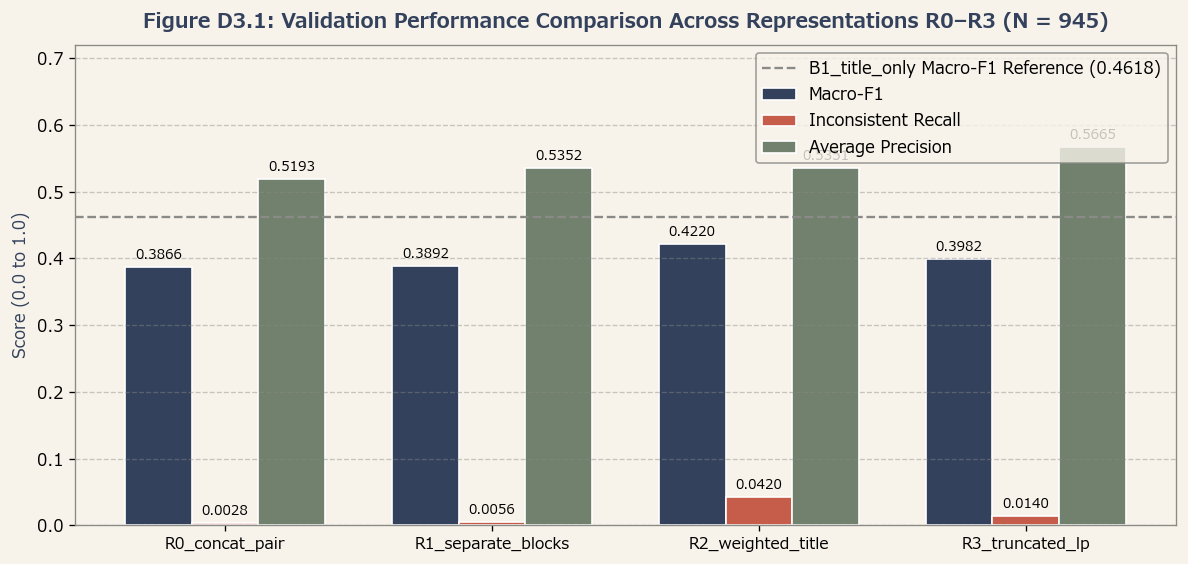

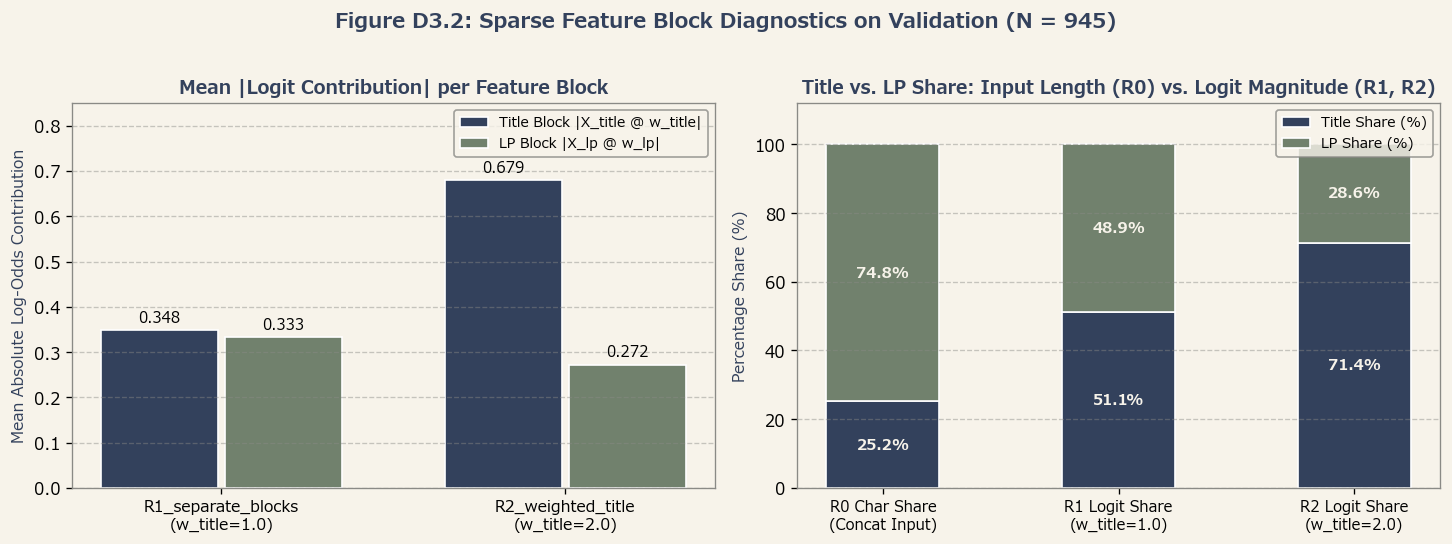

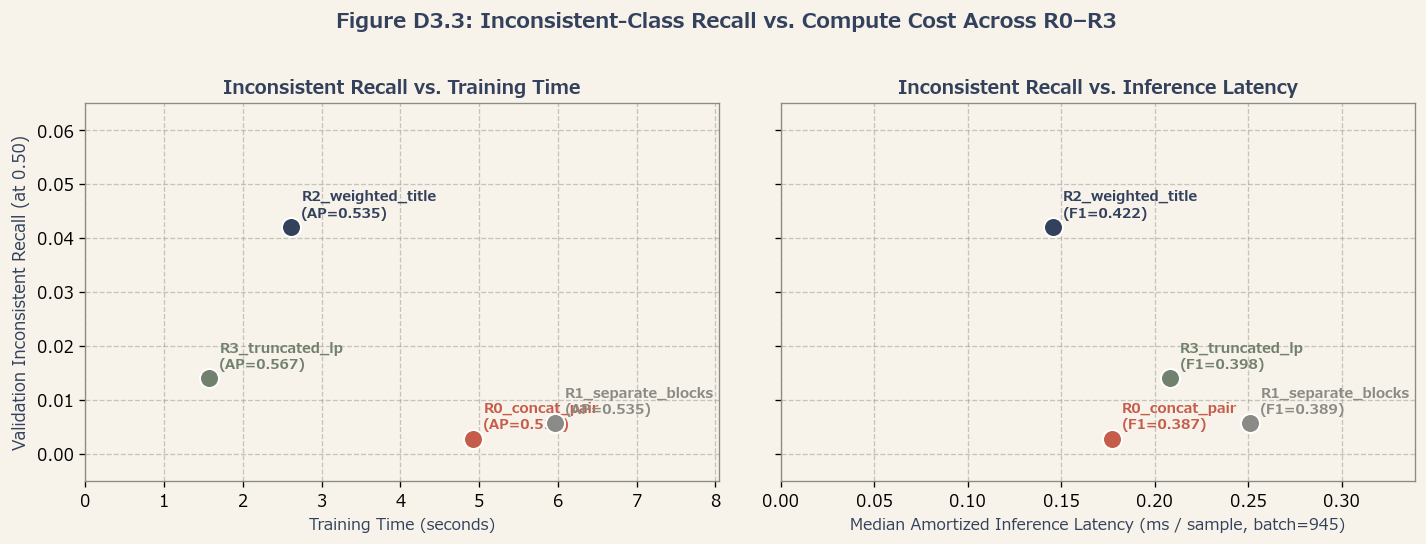

Caption: Up-weighting the title block (R2) lifts Macro-F1 to 0.4220 and recall to 0.0420, while truncating LP to 40 chars (R3) yields the highest AP (0.5665) at lowest training time (1.57 s), yet all remain below B1 Macro-F1 (0.4618).


In [15]:
# TABLE D3 — Controlled Representation Comparison
display(rep_df)

# Detailed sparse shape, model size, and ROC-AUC table
d3_meta_rows = []
for r_id in rep_df['representation_id']:
    info = d3_details[r_id]
    shape = info.get('sparse_matrix_shape') or info['block_diagnostics']['sparse_matrix_shape']
    d3_meta_rows.append({
        'representation_id': r_id,
        'sparse_matrix_shape_valid': str(shape),
        'model_size_mb': info['model_size_mb'],
        'roc_auc': info['roc_auc'],
        'average_precision': info['average_precision'],
    })
display(pd.DataFrame(d3_meta_rows))

# FIGURE D3.1 — Performance Comparison Across R0–R3
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=120)
x = np.arange(len(rep_df))
w = 0.25
b_f1 = ax.bar(x - w, rep_df['macro_f1'], w, label='Macro-F1', color=INDIGO, edgecolor='white')
b_rec = ax.bar(x, rep_df['recall_inconsistent'], w, label='Inconsistent Recall', color=VERMILION, edgecolor='white')
b_ap = ax.bar(x + w, rep_df['average_precision'], w, label='Average Precision', color=MATCHA, edgecolor='white')
ax.axhline(0.4618, color=GRAY, linestyle='--', linewidth=1.4, label='B1_title_only Macro-F1 Reference (0.4618)')
ax.set_title('Figure D3.1: Validation Performance Comparison Across Representations R0–R3 (N = 945)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_ylabel('Score (0.0 to 1.0)', fontsize=10, color=INDIGO)
ax.set_xticks(x)
ax.set_xticklabels(rep_df['representation_id'], fontsize=9.5)
ax.set_ylim(0, 0.72)
ax.grid(axis='y', linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
for bar in list(b_f1) + list(b_rec) + list(b_ap):
    h = bar.get_height()
    ax.annotate(f'{h:.4f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.2)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d3_1_representation_comparison.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE D3.2 — Feature Block Contribution & Norm Diagnostics (R1 vs R2)
r1_bd = d3_details['R1_separate_blocks']['block_diagnostics']
r2_bd = d3_details['R2_weighted_title']['block_diagnostics']
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4), dpi=120)

# Panel 1: Mean absolute linear logit contribution by block
labels_blk = ['R1_separate_blocks\n(w_title=1.0)', 'R2_weighted_title\n(w_title=2.0)']
xb = np.arange(2)
t_logits = [r1_bd['mean_abs_title_logit'], r2_bd['mean_abs_title_logit']]
lp_logits = [r1_bd['mean_abs_lp_logit'], r2_bd['mean_abs_lp_logit']]
bt = axes[0].bar(xb - 0.18, t_logits, 0.34, label='Title Block |X_title @ w_title|', color=INDIGO, edgecolor='white')
bl = axes[0].bar(xb + 0.18, lp_logits, 0.34, label='LP Block |X_lp @ w_lp|', color=MATCHA, edgecolor='white')
axes[0].set_title('Mean |Logit Contribution| per Feature Block', fontsize=11, fontweight='bold', color=INDIGO)
axes[0].set_ylabel('Mean Absolute Log-Odds Contribution', fontsize=9.5, color=INDIGO)
axes[0].set_xticks(xb)
axes[0].set_xticklabels(labels_blk, fontsize=9.5)
axes[0].set_ylim(0, 0.85)
axes[0].grid(axis='y', linestyle='--', alpha=0.45)
axes[0].legend(fontsize=8.5, frameon=True, facecolor=IVORY, edgecolor=GRAY)
for bar in list(bt) + list(bl):
    h = bar.get_height()
    axes[0].annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)

# Panel 2: Percentage share of total logit magnitude (plus R0 char-length share reference)
r0_cs = d3_details['R0_concat_pair']['char_length_share_valid']
share_labels = ['R0 Char Share\n(Concat Input)', 'R1 Logit Share\n(w_title=1.0)', 'R2 Logit Share\n(w_title=2.0)']
title_shares = [r0_cs['mean_title_char_share'] * 100, r1_bd['title_logit_share'] * 100, r2_bd['title_logit_share'] * 100]
lp_shares = [r0_cs['mean_lp_char_share'] * 100, r1_bd['lp_logit_share'] * 100, r2_bd['lp_logit_share'] * 100]
xs = np.arange(3)
axes[1].bar(xs, title_shares, 0.48, label='Title Share (%)', color=INDIGO, edgecolor='white')
axes[1].bar(xs, lp_shares, 0.48, bottom=title_shares, label='LP Share (%)', color=MATCHA, edgecolor='white')
axes[1].set_title('Title vs. LP Share: Input Length (R0) vs. Logit Magnitude (R1, R2)', fontsize=10.8, fontweight='bold', color=INDIGO)
axes[1].set_ylabel('Percentage Share (%)', fontsize=9.5, color=INDIGO)
axes[1].set_xticks(xs)
axes[1].set_xticklabels(share_labels, fontsize=9)
axes[1].set_ylim(0, 112)
axes[1].grid(axis='y', linestyle='--', alpha=0.45)
axes[1].legend(fontsize=8.5, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
for i, (ts, ls) in enumerate(zip(title_shares, lp_shares)):
    axes[1].text(i, ts / 2, f'{ts:.1f}%', ha='center', va='center', color=IVORY, fontweight='bold', fontsize=9)
    axes[1].text(i, ts + ls / 2, f'{ls:.1f}%', ha='center', va='center', color=IVORY, fontweight='bold', fontsize=9)
fig.suptitle('Figure D3.2: Sparse Feature Block Diagnostics on Validation (N = 945)',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d3_2_block_contributions.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE D3.3 — Inconsistent Recall vs Training Time & Inference Latency
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4), dpi=120, sharey=True)
rep_colors = {'R0_concat_pair': VERMILION, 'R1_separate_blocks': GRAY, 'R2_weighted_title': INDIGO, 'R3_truncated_lp': MATCHA}
for _, row in rep_df.iterrows():
    rid = row['representation_id']
    axes[0].scatter(row['train_time_seconds'], row['recall_inconsistent'], s=130, color=rep_colors[rid], edgecolor='white', linewidth=1.2, zorder=4)
    axes[0].annotate(f"{rid}\n(AP={row['average_precision']:.3f})", xy=(row['train_time_seconds'], row['recall_inconsistent']),
                     xytext=(6, 6), textcoords='offset points', fontsize=8.3, color=rep_colors[rid], fontweight='bold')
    axes[1].scatter(row['inference_latency_ms'], row['recall_inconsistent'], s=130, color=rep_colors[rid], edgecolor='white', linewidth=1.2, zorder=4)
    axes[1].annotate(f"{rid}\n(F1={row['macro_f1']:.3f})", xy=(row['inference_latency_ms'], row['recall_inconsistent']),
                     xytext=(6, 6), textcoords='offset points', fontsize=8.3, color=rep_colors[rid], fontweight='bold')
axes[0].set_title('Inconsistent Recall vs. Training Time', fontsize=11, fontweight='bold', color=INDIGO)
axes[0].set_xlabel('Training Time (seconds)', fontsize=9.5, color=INDIGO)
axes[0].set_ylabel('Validation Inconsistent Recall (at 0.50)', fontsize=10, color=INDIGO)
axes[0].set_xlim(0, max(rep_df['train_time_seconds']) * 1.35)
axes[0].set_ylim(-0.005, 0.065)
axes[0].grid(True, linestyle='--', alpha=0.45)
axes[1].set_title('Inconsistent Recall vs. Inference Latency', fontsize=11, fontweight='bold', color=INDIGO)
axes[1].set_xlabel('Median Amortized Inference Latency (ms / sample, batch=945)', fontsize=9.5, color=INDIGO)
axes[1].set_xlim(0, max(rep_df['inference_latency_ms']) * 1.35)
axes[1].grid(True, linestyle='--', alpha=0.45)
fig.suptitle('Figure D3.3: Inconsistent-Class Recall vs. Compute Cost Across R0–R3',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d3_3_recall_vs_cost.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Up-weighting the title block (R2) lifts Macro-F1 to 0.4220 and recall to 0.0420, while truncating LP '
      'to 40 chars (R3) yields the highest AP (0.5665) at lowest training time (1.57 s), yet all remain below B1 Macro-F1 (0.4618).')

**OBSERVATION**:
- `R1_separate_blocks` (97,348 sparse features, weights `1.0 / 1.0`): Lifts Average Precision from `0.5193` -> `0.5352`, but default-threshold Macro-F1 (`0.3892`) and recall (`0.0056`) remain nearly flat. Title and LP blocks contribute almost equally to validation log-odds (`51.1%` vs. `48.9%`).
- `R2_weighted_title` (`w_title = 2.0`, train-CV selected): Raises title logit share to `71.4%` (`mean |logit| = 0.679` vs. `0.272`), lifting default-threshold Macro-F1 from `0.3866` -> **`0.4220`** and inconsistent recall from `0.0028` -> **`0.0420`** (`15x` R0).
- `R3_truncated_lp` (`lp_text[:40]`, train-CV selected): Achieves the highest Average Precision (**`0.5665`**, `+0.0472` over `R0`) and highest ROC-AUC (**`0.7172`**) among pair models at the lowest training time (`1.57 s`), though default-threshold recall remains low (`0.0140`, Macro-F1 `0.3982`).

**INTERPRETATION**: Controlled evidence **partially supports** the length-asymmetry dilution hypothesis—reducing LP dominance (`R2`, `R3`) measurably improves both ranking AP (`R3`) and default-threshold Macro-F1 (`R2`). **However**, none of `R1`–`R3` recovers high `inconsistent` recall (`<= 0.0420`) or surpasses `B1_title_only`'s Macro-F1 (`0.4618`). Thus, length dilution is only a *secondary* contributor; score-scale shift and the inherent inability of additive linear n-grams to verify cross-text entailment/contradiction remain the primary bottlenecks.

**LIMITATION**: `R1`–`R3` remain additive linear models without explicit title-LP interaction terms or class balancing.

## 11. Seen vs. Unseen Landing Page Confounding Check

**QUESTION**: Is the large observed error-rate gap between seen (`~29%`) and unseen (`~53–56%`) landing pages on official validation primarily reflecting differences in class prevalence rather than a drop in balanced classification performance?

**METHOD**: Partition existing M2.0 validation predictions (`N = 945`) into **Seen LP** (exact NFKC-normalized `lp_text` appears in `train`) vs. **Unseen LP** (otherwise). Report sample sizes, class distribution, within-group majority reference error, global training-majority reference error (`B0`), per-class recall, and balanced accuracy. Render **Figure D4.1** (class prevalence & error rates vs. majority references) and **Figure D4.2** (per-class recall by LP group).

> [!NOTE]
> This is strictly a descriptive confounding check on official validation—**not** RQ1 `GroupKFold` evaluation.

,model_id,lp_group,n_samples,consistent_count,inconsistent_count,consistent_pct,inconsistent_pct,within_group_majority_error,train_majority_reference_error,model_error_rate,recall_consistent,recall_inconsistent,balanced_accuracy,macro_f1
0,B0_majority,seen_lp,644,455,189,70.65,29.35,0.2935,0.2935,0.2935,1.0000,0.0000,0.5000,0.4140
1,B0_majority,unseen_lp,301,133,168,44.19,55.81,0.4419,0.5581,0.5581,1.0000,0.0000,0.5000,0.3065
2,B1_title_only,seen_lp,644,455,189,70.65,29.35,0.2935,0.2935,0.2981,0.9626,0.0741,0.5184,0.4737
3,B1_title_only,unseen_lp,301,133,168,44.19,55.81,0.4419,0.5581,0.5282,0.9173,0.1190,0.5182,0.4032
4,B2_lp_only,seen_lp,644,455,189,70.65,29.35,0.2935,0.2935,0.2919,1.0000,0.0053,0.5026,0.4197
5,B2_lp_only,unseen_lp,301,133,168,44.19,55.81,0.4419,0.5581,0.5581,1.0000,0.0000,0.5000,0.3065
6,B3_pair,seen_lp,644,455,189,70.65,29.35,0.2935,0.2935,0.2919,1.0000,0.0053,0.5026,0.4197
7,B3_pair,unseen_lp,301,133,168,44.19,55.81,0.4419,0.5581,0.5581,1.0000,0.0000,0.5000,0.3065


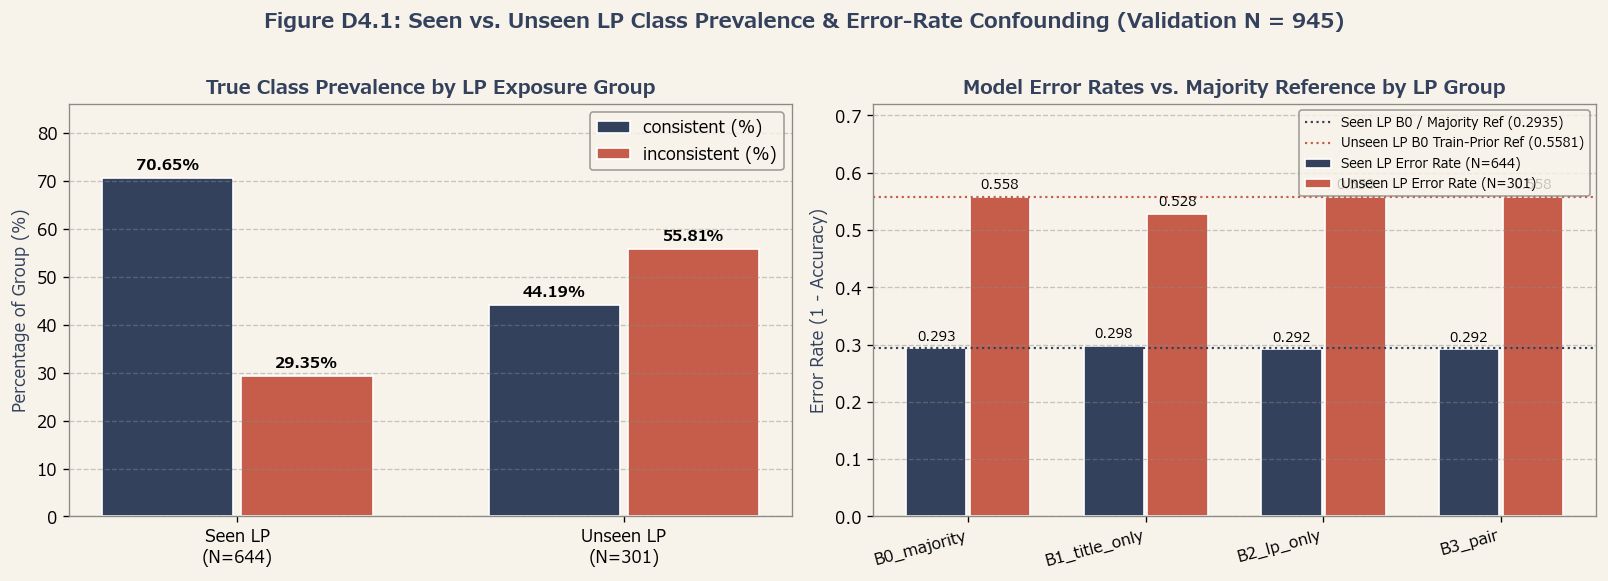

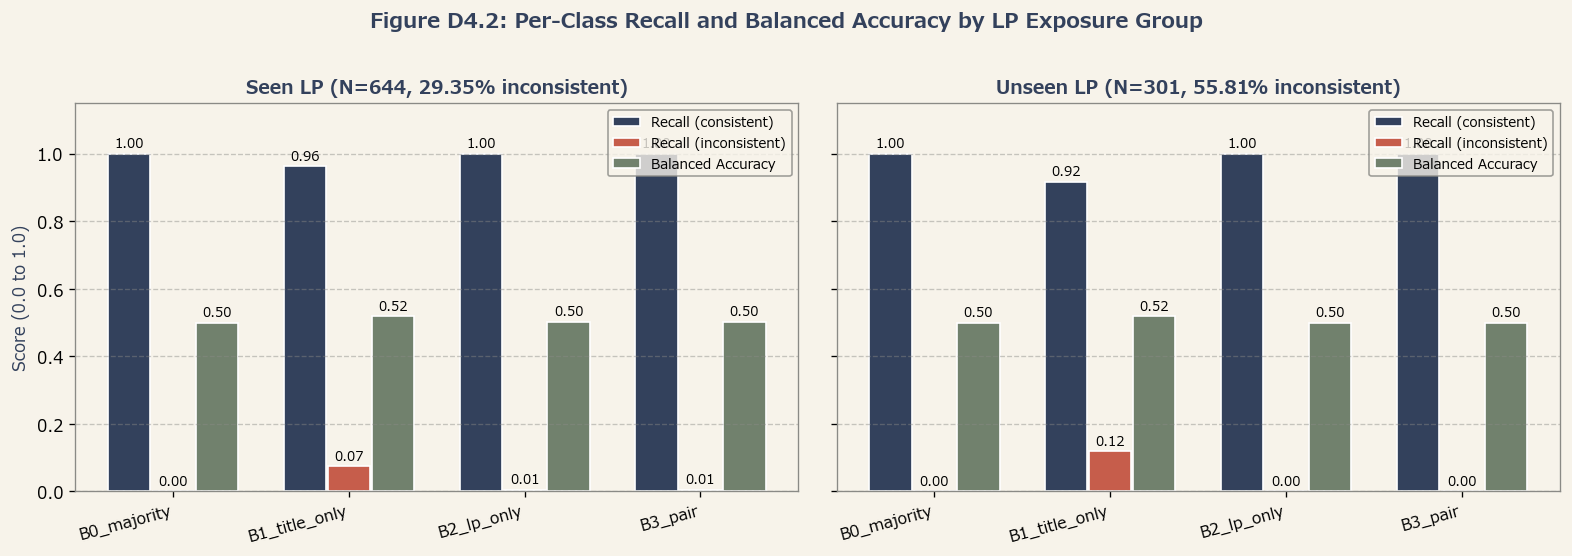

Caption: Balanced accuracy is virtually identical between Seen LP and Unseen LP (e.g., B1: 0.5184 vs. 0.5182), proving the raw 29% vs. 56% error-rate gap is overwhelmingly confounded by flipped class prevalence.


In [16]:
# Display Seen vs. Unseen LP Confounding Table
display(seen_unseen_df)

# FIGURE D4.1 — Class Distribution & Model Error Rates by LP Exposure Group
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7), dpi=120)

# Left panel: Class prevalence in Seen vs Unseen LP
grp_summary = seen_unseen_df[seen_unseen_df['model_id'] == 'B0_majority'].set_index('lp_group')
groups = ['seen_lp', 'unseen_lp']
xg = np.arange(2)
c_pcts = [grp_summary.loc[g, 'consistent_pct'] for g in groups]
i_pcts = [grp_summary.loc[g, 'inconsistent_pct'] for g in groups]
bc = axes[0].bar(xg - 0.18, c_pcts, 0.34, label='consistent (%)', color=INDIGO, edgecolor='white')
bi = axes[0].bar(xg + 0.18, i_pcts, 0.34, label='inconsistent (%)', color=VERMILION, edgecolor='white')
axes[0].set_title('True Class Prevalence by LP Exposure Group', fontsize=11.5, fontweight='bold', color=INDIGO)
axes[0].set_ylabel('Percentage of Group (%)', fontsize=10, color=INDIGO)
axes[0].set_xticks(xg)
axes[0].set_xticklabels([f"Seen LP\n(N={int(grp_summary.loc['seen_lp', 'n_samples'])})",
                         f"Unseen LP\n(N={int(grp_summary.loc['unseen_lp', 'n_samples'])})"], fontsize=10)
axes[0].set_ylim(0, 86)
axes[0].grid(axis='y', linestyle='--', alpha=0.45)
axes[0].legend(frameon=True, facecolor=IVORY, edgecolor=GRAY)
for bar in list(bc) + list(bi):
    h = bar.get_height()
    axes[0].annotate(f'{h:.2f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Right panel: Model error rates vs majority references
m_order = ['B0_majority', 'B1_title_only', 'B2_lp_only', 'B3_pair']
xm = np.arange(len(m_order))
seen_errs = [float(seen_unseen_df[(seen_unseen_df['model_id'] == m) & (seen_unseen_df['lp_group'] == 'seen_lp')]['model_error_rate'].values[0]) for m in m_order]
unseen_errs = [float(seen_unseen_df[(seen_unseen_df['model_id'] == m) & (seen_unseen_df['lp_group'] == 'unseen_lp')]['model_error_rate'].values[0]) for m in m_order]
bs = axes[1].bar(xm - 0.18, seen_errs, 0.34, label='Seen LP Error Rate (N=644)', color=INDIGO, edgecolor='white')
bu = axes[1].bar(xm + 0.18, unseen_errs, 0.34, label='Unseen LP Error Rate (N=301)', color=VERMILION, edgecolor='white')
axes[1].axhline(0.2935, color=INDIGO, linestyle=':', linewidth=1.3, label='Seen LP B0 / Majority Ref (0.2935)')
axes[1].axhline(0.5581, color=VERMILION, linestyle=':', linewidth=1.3, label='Unseen LP B0 Train-Prior Ref (0.5581)')
axes[1].set_title('Model Error Rates vs. Majority Reference by LP Group', fontsize=11.5, fontweight='bold', color=INDIGO)
axes[1].set_ylabel('Error Rate (1 - Accuracy)', fontsize=10, color=INDIGO)
axes[1].set_xticks(xm)
axes[1].set_xticklabels(m_order, rotation=15, ha='right', fontsize=9.5)
axes[1].set_ylim(0, 0.72)
axes[1].grid(axis='y', linestyle='--', alpha=0.45)
axes[1].legend(fontsize=7.8, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
for bar in list(bs) + list(bu):
    h = bar.get_height()
    axes[1].annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.2)
fig.suptitle('Figure D4.1: Seen vs. Unseen LP Class Prevalence & Error-Rate Confounding (Validation N = 945)',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d4_1_seen_unseen_confounding.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE D4.2 — Per-Class Recall & Balanced Accuracy by LP Exposure Group
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.5), dpi=120, sharey=True)
for ax_idx, grp in enumerate(groups):
    ax = axes[ax_idx]
    sub = seen_unseen_df[seen_unseen_df['lp_group'] == grp].set_index('model_id').loc[m_order]
    r_c = ax.bar(xm - 0.25, sub['recall_consistent'], 0.24, label='Recall (consistent)', color=INDIGO, edgecolor='white')
    r_i = ax.bar(xm, sub['recall_inconsistent'], 0.24, label='Recall (inconsistent)', color=VERMILION, edgecolor='white')
    r_b = ax.bar(xm + 0.25, sub['balanced_accuracy'], 0.24, label='Balanced Accuracy', color=MATCHA, edgecolor='white')
    n_g = int(sub['n_samples'].iloc[0])
    title_lbl = f'Seen LP (N={n_g}, 29.35% inconsistent)' if grp == 'seen_lp' else f'Unseen LP (N={n_g}, 55.81% inconsistent)'
    ax.set_title(title_lbl, fontsize=11, fontweight='bold', color=INDIGO)
    ax.set_xticks(xm)
    ax.set_xticklabels(m_order, rotation=15, ha='right', fontsize=9.5)
    ax.set_ylim(0, 1.15)
    ax.grid(axis='y', linestyle='--', alpha=0.45)
    ax.legend(fontsize=8.2, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
    for bar in list(r_c) + list(r_i) + list(r_b):
        h = bar.get_height()
        ax.annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8)
axes[0].set_ylabel('Score (0.0 to 1.0)', fontsize=10, color=INDIGO)
fig.suptitle('Figure D4.2: Per-Class Recall and Balanced Accuracy by LP Exposure Group',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig_d4_2_recall_by_lp_group.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Balanced accuracy is virtually identical between Seen LP and Unseen LP (e.g., B1: 0.5184 vs. 0.5182), '
      'proving the raw 29% vs. 56% error-rate gap is overwhelmingly confounded by flipped class prevalence.')

**OBSERVATION**:
- **Flipped Class Prevalence**: `seen_lp` (`N = 644`) is `70.65%` `consistent` / `29.35%` `inconsistent`, whereas `unseen_lp` (`N = 301`) is `44.19%` `consistent` / **`55.81%` `inconsistent`**.
- **Majority Reference Alignment**: `B0_majority` (which always predicts `consistent`) automatically incurs `0.2935` error on `seen_lp` and `0.5581` error on `unseen_lp` purely due to prevalence shift. `B2_lp_only` and `B3_pair` track `B0` almost identically (`0.2919` vs. `0.5581`).
- **Invariant Balanced Accuracy**: Controlling for class prevalence eliminates the apparent performance cliff: `B1_title_only` achieves `0.5184` Balanced Accuracy on `seen_lp` vs. **`0.5182`** on `unseen_lp` (with slightly higher `inconsistent` recall on `unseen_lp`: `0.1190` vs. `0.0741`), while `B2` and `B3` sit at `0.5026` vs. `0.5000`.

**INTERPRETATION**: **Yes — the M2.0 raw error-rate gap (`~29%` vs. `~56%`) is overwhelmingly confounded by class prevalence differences** between the 13 seen validation landing pages and the 15 unseen validation landing pages. Overall error rate alone MUST NOT be cited as evidence of memorization or unseen-LP generalization failure.

**LIMITATION**: This diagnostic does *not* prove absence of LP memorization—in fact, D2's massive drop from random train-OOF AP (`0.76–0.87`) to validation AP (`0.52–0.55`) strongly motivates controlled LP-group-disjoint evaluation in RQ1.

## 12. Statistical Interpretation: Synthesizing D1–D4

Combining all four diagnostics yields a coherent, evidence-backed explanation of M2.0's baseline failure:

1. **Not Zero Discrimination (D1 [VERIFIED])**: `B1` (`AUC=0.6761`), `B2` (`AUC=0.7448`), and `B3` (`AUC=0.7023`) all rank `inconsistent` above `consistent` substantially better than chance (`0.5000`), and exceed the `0.3778` prevalence baseline in Average Precision (`0.5193–0.5518`).
2. **Severe Score Compression & Train-to-Valid Shift (D1 + D2 [VERIFIED])**: `B2` and `B3` scores on official `valid` are shifted downward (`P95 = 0.2547` and `0.3918`) relative to both `0.50` and their own random 5-fold training-OOF score scale (`selected threshold = 0.40`, `train OOF AP = 0.76–0.87`). Consequently, leak-free training-OOF threshold selection improves `B1` (`F1_inc 0.1623 -> 0.4324`) but fails to recover `B2` (`0.0056`) or `B3` (`0.0806`).
3. **Partial Support for Length Dilution, Not Sole Cause (D3 [VERIFIED])**: Up-weighting title features (`R2`, `w_title=2.0`) increases title logit share from `51.1%` to `71.4%` and raises Macro-F1 (`0.3866 -> 0.4220`); truncating LP text (`R3`, `lp_text[:40]`) yields the best pair AP (`0.5665`). Yet neither resolves default-threshold recall collapse (`<= 0.0420`) or matches `B1` Macro-F1 (`0.4618`).
4. **Prevalence Confounding Explains Raw Error Gap (D4 [VERIFIED])**: `seen_lp` (`29.35%` inconsistent) vs. `unseen_lp` (`55.81%` inconsistent) fully accounts for the `~29% vs ~56%` raw error jump while Balanced Accuracy remains nearly flat (`0.50–0.52`).

## 13. Limitations

1. **No Calibration Analysis**: Raw `predict_proba` outputs are uncalibrated model scores; Platt scaling or isotonic calibration on group-disjoint folds has not yet been tested.
2. **Random CV Fold Overlap in D2/D3**: Training-only 5-fold StratifiedKFold shares the 920 training landing pages across folds, explaining the large gap between train-OOF AP (`~0.86`) and official validation AP (`~0.52`).
3. **Small Unique-LP Count in Official Validation**: Official `valid` (`N = 945`) spans only 28 unique landing pages (13 seen, 15 unseen), creating high variance in LP-level validation statistics.
4. **Additive Linear Classifiers Only**: All `B1`–`B3` and `R0`–`R3` models lack pairwise cross-text interaction features (e.g., lexical overlap, semantic similarity, or cross-attention).
5. **Test Split Untouched & Single Domain**: Official `test` remains frozen; all findings apply strictly to Japanese search advertising consistency under CC BY-NC-SA 4.0.

## 14. Diagnostic Conclusions

| Candidate Failure Mechanism | Verdict | Supporting Evidence [VERIFIED] |
|---|---|---|
| **1. Poor class discrimination** | **Partial / Moderate** | Ranking is clearly above chance (`AUC 0.68–0.74`, `AP 0.52–0.55`), yet precision remains modest (`~0.42–0.55`) when operating at high recall. |
| **2. Unsuitable default threshold + score shift** | **Primary Trigger** | `B2`/`B3` validation scores sit far below `0.50` (`P95 = 0.25–0.39`); even train-OOF `0.40` fails on `B2`/`B3` due to train-to-valid distribution shift. |
| **3. Input representation (length dilution)** | **Secondary Factor** | `R2` (`w_title=2.0`) improves Macro-F1 (`0.3866 -> 0.4220`) and `R3` (`lp[:40]`) improves AP (`0.5193 -> 0.5665`), but default recall remains `<= 0.0420`. |
| **4. Validation LP prevalence confounding** | **Confirmed Confounder** | `seen_lp` (`29.35%` inc) vs. `unseen_lp` (`55.81%` inc) explains the raw error gap (`0.29` vs. `0.56`) while Balanced Accuracy is flat (`0.5184` vs. `0.5182` for `B1`). |

## 15. Next Steps for RQ1–RQ3

Milestone M2.0.1 directly sharpens the experimental designs for the upcoming research milestones (not executed here):

- **RQ1 — Generalization to Unseen Landing Pages (Immediate Recommended Next Experiment)**: Implement `StratifiedGroupKFold` grouped by normalized `lp_text` on `train` to eliminate the `+0.30 AP` random-fold optimism discovered in D2, enabling leak-free unseen-LP generalization testing and group-disjoint threshold/calibration estimation.
- **RQ2 — Lexical vs. Semantic Modeling**: Compare explicit pairwise lexical-interaction features + `class_weight='balanced'` against pretrained Japanese Transformer cross-encoders capable of modeling claim-to-LP entailment and contradiction (overcoming the additive limitation of `R0`–`R3`).
- **RQ3 — Annotation Noise Sensitivity**: Assess how the 92 identical conflicting-label training pairs affect decision boundary calibration and precision-recall stability.

---
*End of Milestone M2.0.1. Official test split remains strictly untouched.*